In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score

from src.evaluate import score

In [2]:
xg = pd.read_parquet("../outputs/xg_oof.parquet")
nn = pd.read_parquet("../outputs/neural_oof.parquet")[["id", "mlp", "deepsets"]]
preds = xg.merge(nn, on="id")

# plain average of the two best, same as in nb 12
preds["blend"] = (preds["xgboost"] + preds["deepsets"]) / 2

va = preds[preds["test"] == False]
te = preds[preds["test"] == True]
print(len(va), "validation shots (out-of-fold),", len(te), "test shots")

74944 validation shots (out-of-fold), 24802 test shots


In [3]:
def bestCut(y, p):
    """cut-off with the best F1 on validation, tried every 0.01"""
    best = 0.5
    bestF1 = 0
    for cut in np.arange(0.05, 0.95, 0.01):
        f1 = f1_score(y, p >= cut, zero_division=0)
        if f1 > bestF1:
            bestF1 = f1
            best = cut
    return round(best, 2)

In [4]:
models = ["logregBasic", "logreg", "xgboost", "mlp", "deepsets", "blend"]
names = {
    "logregBasic": "Logistic regression, distance + angle",
    "logreg": "Logistic regression, all features",
    "xgboost": "XGBoost, tuned",
    "mlp": "MLP",
    "deepsets": "Deep Sets",
    "blend": "XGBoost + Deep Sets average",
}

# always guessing the training goal rate. at a 0.5 cut it says no goal every time
rate = va["goal"].mean()
rows = [{
    "model": "Always guess the training goal rate",
    "validationAuc": 0.5,
    "testAuc": 0.5,
    "testBrier": ((te["goal"] - rate) ** 2).mean(),
    "cut": 0.5,
    "testAccuracy": (te["goal"] == 0).mean(),
    "testPrecision": 0.0,
    "testRecall": 0.0,
    "testF1": 0.0,
}]

for m in models:
    # the cut is picked on validation and then used as it is on test
    cut = bestCut(va["goal"], va[m])
    hit = te[m] >= cut
    rows.append({
        "model": names[m],
        "validationAuc": score(va["goal"], va[m])["auc"],
        "testAuc": score(te["goal"], te[m])["auc"],
        "testBrier": score(te["goal"], te[m])["brier"],
        "cut": cut,
        "testAccuracy": accuracy_score(te["goal"], hit),
        "testPrecision": precision_score(te["goal"], hit, zero_division=0),
        "testRecall": recall_score(te["goal"], hit),
        "testF1": f1_score(te["goal"], hit),
    })

table = pd.DataFrame(rows)
table.round(3)

,model,validationAuc,testAuc,testBrier,cut,testAccuracy,testPrecision,testRecall,testF1
0,Always guess the training goal rate,0.500,0.500,0.093,0.50,0.897,0.000,0.000,0.000
1,"Logistic regression, distance + angle",0.741,0.725,0.085,0.17,0.786,0.224,0.433,0.295
2,"Logistic regression, all features",0.802,0.793,0.078,0.18,0.852,0.345,0.481,0.402
3,"XGBoost, tuned",0.811,0.802,0.076,0.22,0.869,0.388,0.458,0.420
4,MLP,0.805,0.798,0.077,0.22,0.863,0.370,0.458,0.409
5,Deep Sets,0.806,0.798,0.077,0.19,0.845,0.336,0.514,0.406
6,XGBoost + Deep Sets average,0.811,0.802,0.076,0.22,0.866,0.378,0.464,0.417


In [5]:
cut = bestCut(va["goal"], va["xgboost"])
hit = te["xgboost"] >= cut
print("xgboost on test at cut", cut)
pd.crosstab(te["goal"], hit, rownames=["goal"], colnames=["predicted goal"])

xgboost on test at cut 0.22


predicted goal,False,True
goal,,
0,20390,1851
1,1388,1173


In [6]:
# resample whole test matches 1000 times. shots from one match aren't independent, so matches are the unit
rng = np.random.default_rng(2026)
y = te["goal"].values
matchIds = te["match_id"].values
groups = []
for m in np.unique(matchIds):
    groups.append(np.where(matchIds == m)[0])

aucs = {}
for m in models:
    aucs[m] = []

for b in range(1000):
    pick = rng.integers(0, len(groups), len(groups))
    parts = []
    for i in pick:
        parts.append(groups[i])
    idx = np.concatenate(parts)
    for m in models:
        aucs[m].append(roc_auc_score(y[idx], te[m].values[idx]))

low = [0.5]
high = [0.5]
for m in models:
    low.append(np.percentile(aucs[m], 2.5))
    high.append(np.percentile(aucs[m], 97.5))
table["testAucLow"] = low
table["testAucHigh"] = high
table[["model", "testAuc", "testAucLow", "testAucHigh"]].round(3)

,model,testAuc,testAucLow,testAucHigh
0,Always guess the training goal rate,0.500,0.500,0.500
1,"Logistic regression, distance + angle",0.725,0.714,0.735
2,"Logistic regression, all features",0.793,0.783,0.802
3,"XGBoost, tuned",0.802,0.792,0.811
4,MLP,0.798,0.789,0.808
5,Deep Sets,0.798,0.789,0.808
6,XGBoost + Deep Sets average,0.802,0.793,0.811


In [7]:
# is the gap to xgboost real? same resamples for both models, so the difference is paired
for m in ["deepsets", "blend", "logreg"]:
    diff = np.array(aucs[m]) - np.array(aucs["xgboost"])
    print(m, "minus xgboost:", round(diff.mean(), 4), "95% range", round(np.percentile(diff, 2.5), 4), "to", round(np.percentile(diff, 97.5), 4))

deepsets minus xgboost: -0.0036 95% range -0.0064 to -0.0007
blend minus xgboost: -0.0 95% range -0.0015 to 0.0015
logreg minus xgboost: -0.0092 95% range -0.0124 to -0.0058


In [8]:
table.to_csv("../outputs/table2_goal.csv", index=False)
print("saved")

saved


In [9]:
import os
import matplotlib.pyplot as plt
from xgboost import XGBClassifier, DMatrix

shots = pd.read_parquet("../data/features/shots_features.parquet")
skip = ["id", "match_id", "test", "fold", "goal", "x", "y"]
cols = []
for c in shots.columns:
    if c not in skip:
        cols.append(c)
shotsTr = shots[shots["test"] == False]
shotsTe = shots[shots["test"] == True]
print(len(cols), "inputs")

42 inputs


In [10]:
def newXgb():
    """the tuned settings from nb 05"""
    return XGBClassifier(n_estimators=400, max_depth=3, min_child_weight=1, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8, reg_lambda=5,
                         eval_metric="logloss", random_state=42, n_jobs=-1)


def xgbFolds(use):
    """out-of-fold auc on train, then a final model on all of train scored on test. only the columns in use"""
    oof = np.zeros(len(shotsTr))
    for k in range(1, 6):
        isK = (shotsTr["fold"] == k).values
        a = shotsTr[~isK]
        b = shotsTr[isK]
        med = a[use].median()
        model = newXgb()
        model.fit(a[use].fillna(med), a["goal"])
        oof[isK] = model.predict_proba(b[use].fillna(med))[:, 1]

    med = shotsTr[use].median()
    model = newXgb()
    model.fit(shotsTr[use].fillna(med), shotsTr["goal"])
    testPred = model.predict_proba(shotsTe[use].fillna(med))[:, 1]
    return roc_auc_score(shotsTr["goal"], oof), roc_auc_score(shotsTe["goal"], testPred), model, med

In [11]:
frameCols = ["visible", "defendersInCone", "teammatesInCone", "nearestDefender", "defendersWithin3",
             "keeperMissing", "keeperInCone", "keeperToGoal", "keeperToShooter"]
flagCols = ["under_pressure", "shot_first_time", "shot_one_on_one", "shot_open_goal",
            "shot_aerial_won", "shot_follows_dribble", "shot_redirect"]
oneHot = []
for c in cols:
    if c.startswith("shot_body_part_") or c.startswith("shot_technique_") or c.startswith("shot_type_") or c.startswith("play_pattern_"):
        oneHot.append(c)

dropGroups = {
    "all features": [],
    "minus freeze frame": frameCols,
    "minus flags": flagCols,
    "minus body part, technique, type, play pattern": oneHot,
    "minus distance and angle": ["distance", "angle"],
}

abl = []
for name in dropGroups:
    use = []
    for c in cols:
        if c not in dropGroups[name]:
            use.append(c)
    v, t, model, med = xgbFolds(use)
    abl.append({"model": "XGBoost, " + name, "inputs": len(use), "validationAuc": v, "testAuc": t})
    print(name, len(use), "inputs:", round(v, 4), round(t, 4))
    if name == "all features":
        fullModel = model
        fullMed = med

ablation = pd.DataFrame(abl)
ablation.to_csv("../outputs/ablation_xgboost.csv", index=False)
ablation.round(3)

all features 42 inputs: 0.8105 0.8018
minus freeze frame 33 inputs: 0.7919 0.7844
minus flags 35 inputs: 0.81 0.8009
minus body part, technique, type, play pattern 18 inputs: 0.8055 0.7928
minus distance and angle 40 inputs: 0.7979 0.7907


,model,inputs,validationAuc,testAuc
0,"XGBoost, all features",42,0.811,0.802
1,"XGBoost, minus freeze frame",33,0.792,0.784
2,"XGBoost, minus flags",35,0.810,0.801
3,"XGBoost, minus body part, technique, type, pla...",18,0.806,0.793
4,"XGBoost, minus distance and angle",40,0.798,0.791


In [12]:
# shap values straight from xgboost (pred_contribs is the same treeshap maths as the shap library)
sample = shotsTe.sample(5000, random_state=2026)
Xs = sample[cols].fillna(fullMed)
contrib = fullModel.get_booster().predict(DMatrix(Xs), pred_contribs=True)
shapVals = contrib[:, :-1]  # last column is the starting value, not a feature

# shap values plus the starting value add up to the model's score, so this should be ~0
total = 1 / (1 + np.exp(-contrib.sum(axis=1)))
print("biggest gap between shap total and prediction:", np.abs(total - fullModel.predict_proba(Xs)[:, 1]).max())

biggest gap between shap total and prediction: 4.917383e-07


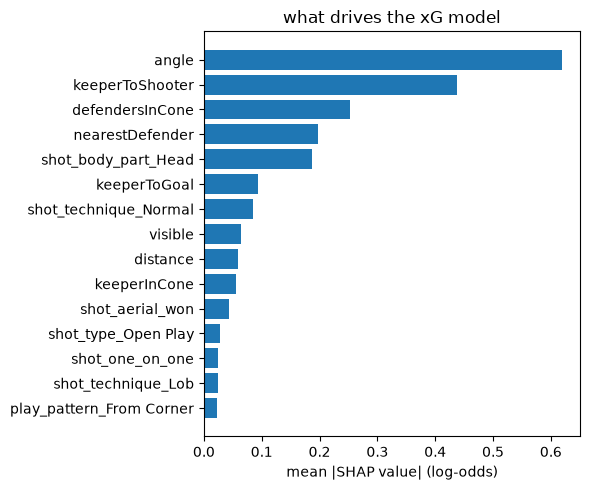

angle                    0.619
keeperToShooter          0.437
defendersInCone          0.252
nearestDefender          0.198
shot_body_part_Head      0.187
keeperToGoal             0.094
shot_technique_Normal    0.086
visible                  0.064
distance                 0.060
keeperInCone             0.056
dtype: float32

In [13]:
meanAbs = pd.Series(np.abs(shapVals).mean(axis=0), index=cols).sort_values()
top = meanAbs.tail(15)
plt.figure(figsize=(6, 5))
plt.barh(top.index, top.values)
plt.xlabel("mean |SHAP value| (log-odds)")
plt.title("what drives the xG model")
plt.tight_layout()
plt.savefig("../outputs/shap_importance.png", dpi=200)
plt.show()
meanAbs.sort_values(ascending=False).head(10).round(3)

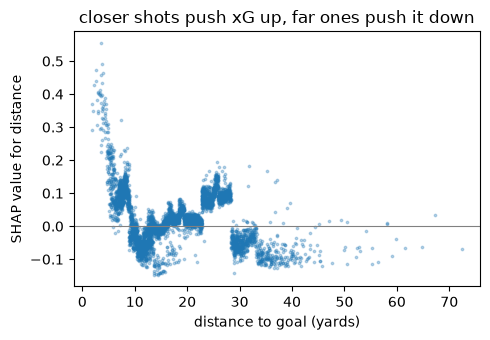

In [14]:
d = cols.index("distance")
plt.figure(figsize=(5, 3.5))
plt.scatter(sample["distance"], shapVals[:, d], s=3, alpha=0.3)
plt.axhline(0, color="grey", linewidth=0.8)
plt.xlabel("distance to goal (yards)")
plt.ylabel("SHAP value for distance")
plt.title("closer shots push xG up, far ones push it down")
plt.tight_layout()
plt.savefig("../outputs/shap_distance.png", dpi=200)
plt.show()

In [15]:
os.makedirs("../outputs/models", exist_ok=True)
fullModel.save_model("../outputs/models/xgboost_goal.json")
fullMed.to_json("../outputs/models/xgboost_goal_medians.json")
print("saved model and medians")

saved model and medians
